# This is a notebook that predicts customer churn for a tel communication company

## Data is coming from kaggle and the steps are:
- Environment creation
- Data collection
- Data preparation
- Exploratory Data Analysis (EDA)
- Feature engineering
- Model development
- Results

### Step 0: Environment creation
In this step the required packages will be downloaded and imported into the working environment

In [47]:
#%pip install numpy; pandas; matplotlib; scikit-learn; kagglehub; imblearn; xgboost

In [48]:
import pandas as pd
import sklearn
import kagglehub

import matplotlib.pyplot as plt
import seaborn as sns


### Step 1: Data fetching

In [49]:
handle = 'blastchar/telco-customer-churn'
path = 'Data'

dataset = kagglehub.dataset_download(handle=handle, output_dir=path)

df = pd.read_csv(f'{path}\\WA_Fn-UseC_-Telco-Customer-Churn.csv')

print(df.head())

print(f"Data columns: {df.columns}")

print(df.dtypes)

print(df.isna().sum())


   customerID  gender  SeniorCitizen  ... MonthlyCharges TotalCharges  Churn
0  7590-VHVEG  Female              0  ...          29.85        29.85     No
1  5575-GNVDE    Male              0  ...          56.95       1889.5     No
2  3668-QPYBK    Male              0  ...          53.85       108.15    Yes
3  7795-CFOCW    Male              0  ...          42.30      1840.75     No
4  9237-HQITU  Female              0  ...          70.70       151.65    Yes

[5 rows x 21 columns]
Data columns: Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='str')
customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents 

#### Step 1 conclusions

- There are no missing values
- Dataset contains 21 columns
- Most columns are yes/no which can be turned into boolean 1/0 as "senior" column
- There are some string columns that needs to be encoded
- Total charges column is of string type and should be converted to float

### Step 2: Data Preparation

In [50]:
from sklearn.preprocessing import LabelEncoder
#Drop customer id column since it isn;t relevant
if 'customerID' in df.columns.values:
    df.drop(columns=['customerID'], inplace=True)

#Identify service add-ons and replace no internet/phone service with no since it is perfectly correlated with internet/phone service columns
service_addons = [
    "MultipleLines",
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies",
]

df[service_addons] = df[service_addons].replace({
    "No phone service": "No",
    "No internet service": "No",
})

#Transform Yes/No columns into 1/0
#Determine Yes/No(Binary) Columns 
yes_no = {"Yes", "No"}
binary_cols = [
    col for col in df.select_dtypes(include=['object', 'string']).columns
    if set(df[col].unique()).issubset(yes_no)
]
print(f"Binary columns: f{binary_cols}")

#Determine non-binary columns(Yes/No/Third Option) for visualization
non_binary_cols = [
    col for col in df.select_dtypes(include=['string']).columns
    if not set(df[col].unique()).issubset(yes_no)
]
print(f"Non Binary Columns: f{non_binary_cols}")

#Binary columns replacement
df[binary_cols] = df[binary_cols].replace({'Yes': 1, 'No':0}).astype(int)
#Gender columns replacement
df['gender'] = df['gender'].replace({'Male':1, 'Female':0}).astype(int)

#Set total charges dtype to float
df = df[df["TotalCharges"].astype("string").str.strip().ne("")].copy()
df["TotalCharges"] = df["TotalCharges"].astype(float)

print(df['OnlineSecurity'].value_counts())
print(df['Partner'].value_counts())
print(df['gender'].value_counts())
print(df['TotalCharges'].value_counts())
print(df['Churn'].value_counts())

text_data_features = ['InternetService', 'Contract', 'PaymentMethod']
le = LabelEncoder()
for feature in text_data_features:
    df[feature] = le.fit_transform(df[feature])
    print(feature,' : ',df[feature].unique(),' = ', le.inverse_transform(df[feature].unique()))

df.describe()


Binary columns: f['Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'PaperlessBilling', 'Churn']
Non Binary Columns: f['gender', 'InternetService', 'Contract', 'PaymentMethod', 'TotalCharges']
OnlineSecurity
0    5017
1    2015
Name: count, dtype: int64
Partner
0    3639
1    3393
Name: count, dtype: int64
gender
1    3549
0    3483
Name: count, dtype: int64
TotalCharges
20.20      11
19.75       9
19.90       8
20.05       8
19.65       8
           ..
1990.50     1
7362.90     1
346.45      1
306.60      1
6844.50     1
Name: count, Length: 6530, dtype: int64
Churn
0    5163
1    1869
Name: count, dtype: int64
InternetService  :  [0 1 2]  =  ['DSL' 'Fiber optic' 'No']
Contract  :  [0 1 2]  =  ['Month-to-month' 'One year' 'Two year']
PaymentMethod  :  [2 3 0 1]  =  ['Electronic check' 'Mailed check' 'Bank transfer (automatic)'
 'Credit card (automatic)']


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
count,7032.000000,7032.000000,7032.000000,7032.000000,7032.000000,7032.000000,7032.000000,7032.000000,7032.000000,7032.000000,7032.000000,7032.000000,7032.000000,7032.000000,7032.000000,7032.000000,7032.000000,7032.000000,7032.000000,7032.000000
mean,0.504693,0.162400,0.482509,0.298493,32.421786,0.903299,0.421928,0.872582,0.286547,0.344852,0.343857,0.290102,0.384386,0.388367,0.688567,0.592719,1.573237,64.798208,2283.300441,0.265785
std,0.500014,0.368844,0.499729,0.457629,24.545260,0.295571,0.493902,0.737271,0.452180,0.475354,0.475028,0.453842,0.486484,0.487414,0.832934,0.491363,1.067504,30.085974,2266.771362,0.441782
min,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,18.250000,18.800000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,9.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,35.587500,401.450000,0.000000
50%,1.000000,0.000000,0.000000,0.000000,29.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2.000000,70.350000,1397.475000,0.000000
75%,1.000000,0.000000,1.000000,1.000000,55.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,2.000000,89.862500,3794.737500,1.000000
max,1.000000,1.000000,1.000000,1.000000,72.000000,1.000000,1.000000,2.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,2.000000,1.000000,3.000000,118.750000,8684.800000,1.000000


### Step 3: Exploratory Data Analysis

#### Step 3.1 Create a Pie Chart to visualize churn

<Axes: title={'center': 'Customer Churn'}>

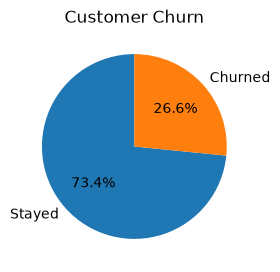

In [51]:
churn_pie = df['Churn'].value_counts().rename(index={0:'Stayed', 1:'Churned'})

churn_pie.plot(kind='pie', figsize=(3,3), autopct="%1.1f%%", startangle=90, title='Customer Churn')

### Step 3.2 create a brief Exploratory Data Analysis

Text(0.5, 1.0, 'Numeric values Correlation Matrix')

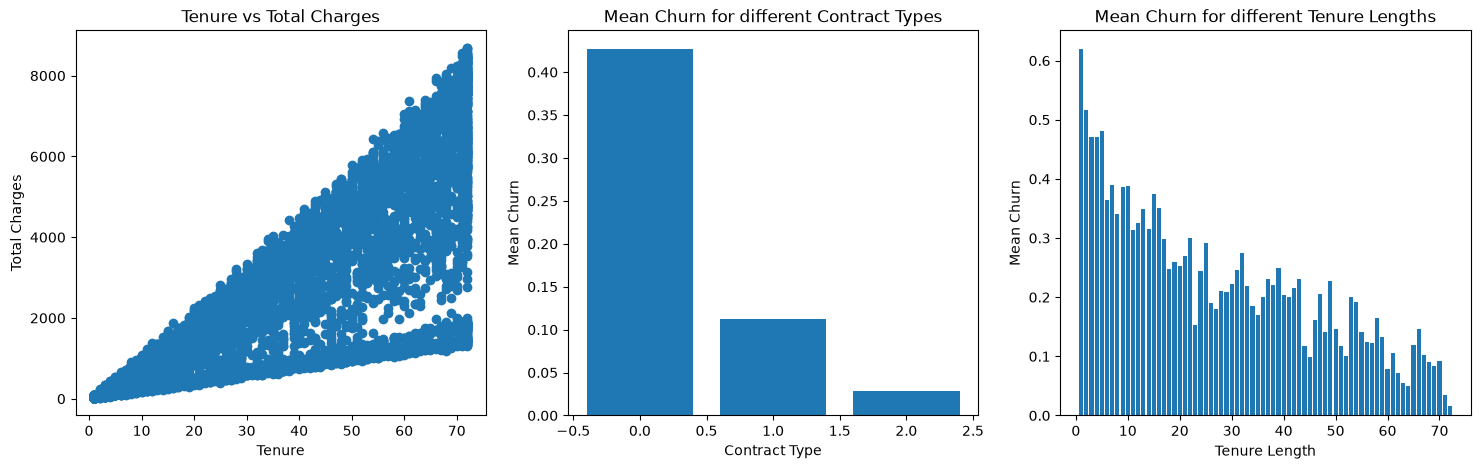

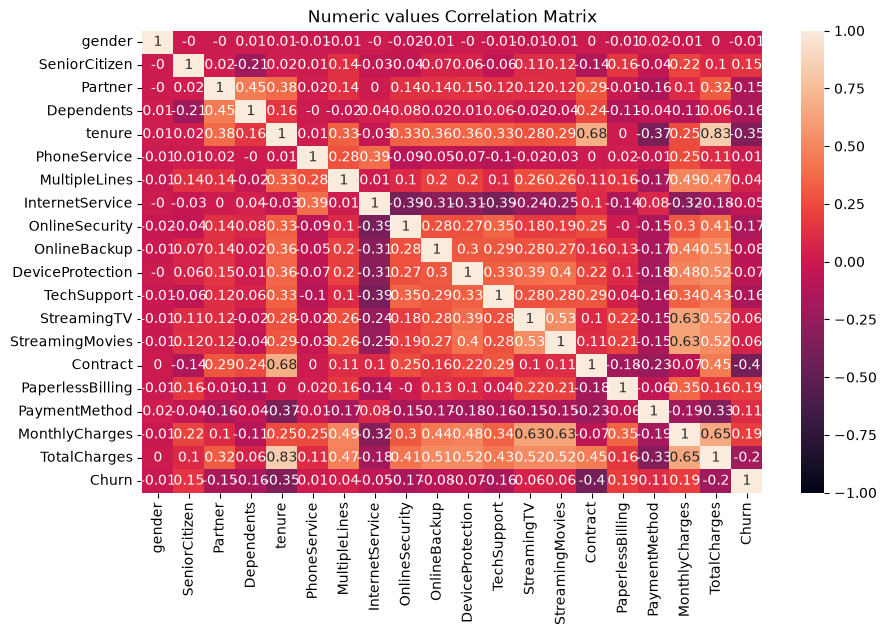

In [52]:
fig = plt.figure(figsize=(18, 5))

#Create a scatter plot to visualize the relationship between tenure and total charge
plt.subplot(131)
plt.scatter(x=df['tenure'], y=df['TotalCharges'])
plt.title('Tenure vs Total Charges')
plt.xlabel('Tenure')
plt.ylabel('Total Charges')

#Create a barplot to show a histogram of churn rate by contract type
plt.subplot(132)
df_churn_contract = df.groupby('Contract')['Churn'].mean().reset_index()
plt.bar(x=df_churn_contract['Contract'], height=df_churn_contract['Churn'])
plt.title('Mean Churn for different Contract Types')
plt.xlabel('Contract Type')
plt.ylabel('Mean Churn')

#Create a barplot to show a histogram of churn rate by Tenure
plt.subplot(133)
df_churn_tenure = df.groupby('tenure')['Churn'].mean().reset_index()
plt.bar(x=df_churn_tenure['tenure'], height=df_churn_tenure['Churn'])
plt.title("Mean Churn for different Tenure Lengths")
plt.xlabel("Tenure Length")
plt.ylabel("Mean Churn")

#Create a correlation heatmap for numeric columns

df_correlation = df.select_dtypes(include=['int', 'float'])
cm = df_correlation.corr().round(2)

fig = plt.figure(figsize=(10,6))
sns.heatmap(data = cm, annot=True, vmin=-1, vmax=1)
plt.title('Numeric values Correlation Matrix')

### Step 4 - Feature Engineering

#### Determine which features will be used in the modeling phase

- Separate the features into numerical and categorical features for separate processing

In [53]:
categorical_features = []
numerical_features = []

for feature in df.columns.values:
    if len(df[feature].unique()) < 5:
        categorical_features.append(feature)
    else:
        numerical_features.append(feature)

categorical_features.remove('Churn')

print('Categorical Features :', categorical_features)
print('Numerical Features :', numerical_features)

Categorical Features : ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
Numerical Features : ['tenure', 'MonthlyCharges', 'TotalCharges']


- Analyze the categorical features to see which ones add information to the model and which not using Chi Squared Values

Text(0.5, 1.0, 'Selection of Categorical Features')

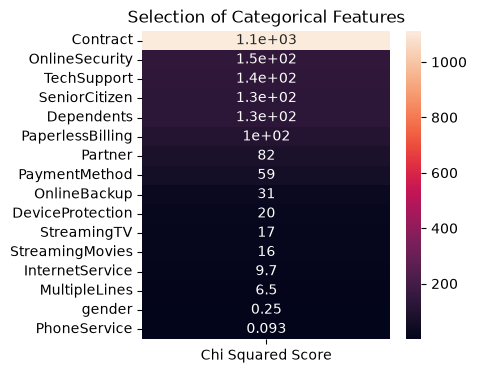

In [54]:
from sklearn.feature_selection import SelectKBest, chi2, mutual_info_classif

features = df.loc[:, categorical_features]
target = df.loc[:, 'Churn']

features.head()

best_features = SelectKBest(score_func=chi2, k='all')
fit = best_features.fit(features, target)

feature_scores = pd.DataFrame(data=fit.scores_, index=features.columns.values, columns=['Chi Squared Score'])

fig = plt.figure(figsize=(4,4))
sns.heatmap(feature_scores.sort_values(ascending=False, by='Chi Squared Score'), annot=True)
plt.title('Selection of Categorical Features')

- Analyze the numerical features using ANOVA

,SeniorCitizen,Dependents,tenure,OnlineSecurity,TechSupport,Contract,PaperlessBilling,MonthlyCharges,TotalCharges,Churn
0,0,0,1,0,0,0,1,29.85,29.85,0
1,0,0,34,1,0,1,0,56.95,1889.50,0
2,0,0,2,1,0,0,1,53.85,108.15,1
3,0,0,45,1,1,1,0,42.30,1840.75,0
4,0,0,2,0,0,0,1,70.70,151.65,1
...,...,...,...,...,...,...,...,...,...,...
7038,0,1,24,1,1,1,1,84.80,1990.50,0
7039,0,1,72,0,0,1,1,103.20,7362.90,0
7040,0,1,11,1,0,0,1,29.60,346.45,0
7041,1,0,4,0,0,0,1,74.40,306.60,1


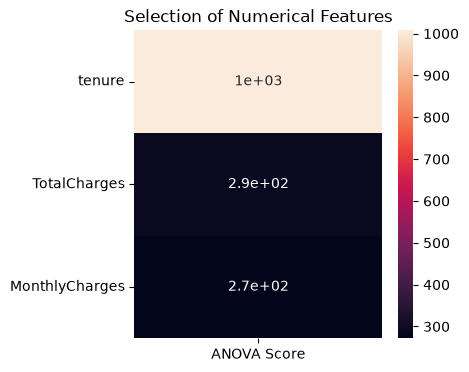

In [55]:
from sklearn.feature_selection import f_classif

features = df.loc[:, numerical_features]
target = df.loc[:, 'Churn']

best_features = SelectKBest(score_func=f_classif, k='all')
fit = best_features.fit(features, target)

feature_scores = pd.DataFrame(data=fit.scores_, index=(features.columns.values), columns=['ANOVA Score'])

fig = plt.figure(figsize=(4,4))
sns.heatmap(feature_scores.sort_values(by='ANOVA Score', ascending=False), annot=True)
plt.title('Selection of Numerical Features')

df.drop(columns=['PhoneService', 'gender', 'MultipleLines', 'InternetService', 'StreamingMovies', 'StreamingTV', 'DeviceProtection', 'OnlineBackup', 'PaymentMethod', 'Partner'])

- Based on the findings above there are two conclusions
    - Categorical Features below Payment method will be dropped due to low importance of the feature
    - Numerical features will be kept as it is

### Step 4 - Model Creation

In [62]:
from imblearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import log_loss

X = df.drop(columns='Churn')
y = df['Churn']


preprocessor = ColumnTransformer([
    ('numeric', StandardScaler(),
     make_column_selector(dtype_include='number')),
])


pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000)),
])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

model = GridSearchCV(
    pipeline,
    {"classifier__C": [0.01, 0.1, 1, 10]},
    cv=cv,
    scoring="average_precision",
)

model.fit(X_train, y_train)

y_hat = model.predict(X_test)
yhat_prob = model.predict_proba(X_test)

print(f"Binary Cross Entropy loss: {log_loss(y_test, yhat_prob)}")


Binary Cross Entropy loss: 0.42935200412163704


### Step 5 - Results

ROC AUC:           0.835
Accuracy:          0.793
Precision:         0.622
Recall:            0.564
F1:                0.592


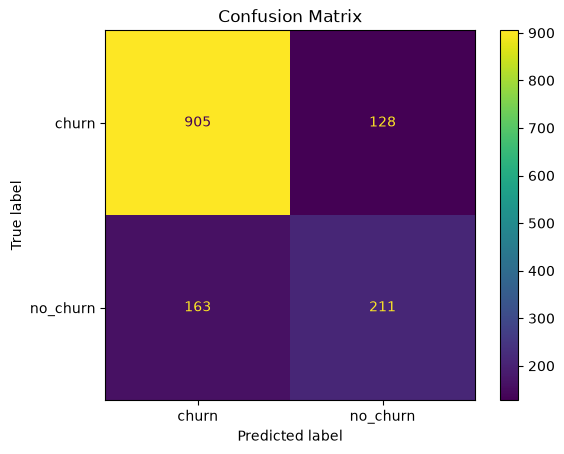

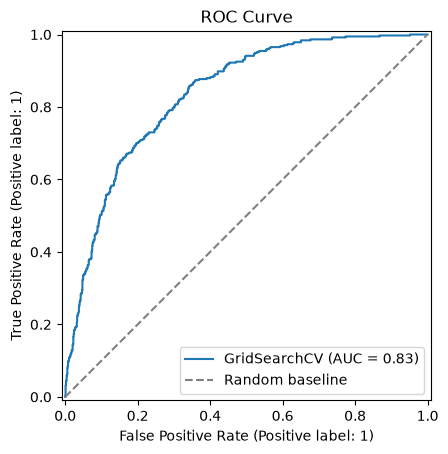

In [63]:
from sklearn.metrics import (
    RocCurveDisplay,
    ConfusionMatrixDisplay,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
)

y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]  # probability of class 1 (Churn)

print(f"ROC AUC:           {roc_auc_score(y_test, y_prob):.3f}")
print(f"Accuracy:          {accuracy_score(y_test, y_pred):.3f}")
print(f"Precision:         {precision_score(y_test, y_pred):.3f}")
print(f"Recall:            {recall_score(y_test, y_pred):.3f}")
print(f"F1:                {f1_score(y_test, y_pred):.3f}")

#Confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_hat,
    labels=[0, 1],
    display_labels=['churn', 'no_churn']
)
plt.title('Confusion Matrix')

# ROC AUC plot 
fig, ax = plt.subplots()
RocCurveDisplay.from_estimator(model, X_test, y_test, ax=ax)
ax.plot([0, 1], [0, 1], "--", color="gray", label="Random baseline")
ax.set_title('ROC Curve')
ax.legend()



### Conclusions

- Churn is associated with contract type and tenure. The notebook’s charts show much higher average churn for month-to-month contracts (about 43%) than one-year (about 11%) or two-year contracts (about 3%). Churn also generally decreases as tenure increases. These are associations in this dataset, not proof that changing a customer’s contract would itself prevent churn.
- The model separates churners from non-churners reasonably well, but its decisions miss many churners. Test ROC AUC is 0.835, while churn-class recall is 0.564 and F1 is 0.592. At the current classification threshold, it identifies about 56% of churners and misses about 44%. Precision of 0.622 means around 38% of customers it flags would not churn.
- Accuracy (0.793) is not the whole story. The churn class is the minority, so accuracy alone could make performance seem better than its ability to find churners. Whether the current precision/recall balance is useful depends on the costs of missed churners versus unnecessary retention offers.
- Treat the feature-score plots cautiously. The notebook label-encodes categories as numbers, then the model pipeline selects string columns for one-hot encoding. Since those categories have already become numeric, they may instead be treated as ordered numeric values. One-hot encoding the original categories inside the pipeline would avoid implying an artificial order.